# 01 — Veri Analizi (EDA) ve Süre Tahmini (ETA) Modeli

**Bitirme projesi:** Yapay Zeka Destekli Gerçek Zamanlı Araç Rota Optimizasyonu Platformu

Bu notebook projenin ilk iki haftasını kapsar:

1. NYC Taxi verisini tanımak (EDA)
2. Veriyi temizlemek ve özellik çıkarmak
3. Üç modeli karşılaştırmak: **taban çizgi**, **Linear Regression**, **XGBoost**
4. En iyi modeli kaydetmek
5. Bonus: modelin tahmin ettiği sürelerle **OR-Tools** kullanarak küçük bir rota problemi çözmek

### Hazırlık

1. Kaggle'da **New York City Taxi Trip Duration** yarışmasına gir (Data sekmesi) ve `train.zip` dosyasını indir.
2. İçindeki `train.csv` dosyasını bu notebook ile aynı klasöre koy.
3. Gerekli paketleri kur (terminalde bir kez):

```
pip install pandas numpy matplotlib scikit-learn xgboost ortools joblib
```

> İpucu: Veri ~1,4 milyon satır. Bilgisayarın yavaşsa aşağıdaki `SAMPLE_SIZE` değerini `300_000` yap; sonuçlar hemen hemen aynı çıkar.

In [3]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import MiniBatchKMeans
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

DATA_PATH = r"C:\Users\DELL\OneDrive\Desktop\nyc-taxi-trip-duration\train.zip"   # Kaggle verisi (zip doğrudan okunur)
SAMPLE_SIZE = None          # None = tüm veri; hızlı deneme için 300_000 gibi bir sayı yaz
RANDOM_STATE = 42
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True

In [4]:
df = pd.read_csv(DATA_PATH, parse_dates=["pickup_datetime", "dropoff_datetime"])
if SAMPLE_SIZE is not None and len(df) > SAMPLE_SIZE:
    df = df.sample(SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)

print(f"Satır sayısı: {len(df):,}")
df.head()

Satır sayısı: 1,458,644


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


## 1. Genel bakış

Sütunların tipine, boş değer olup olmadığına ve temel istatistiklere bakıyoruz. `trip_duration` **saniye** cinsinden ve tahmin etmeye çalıştığımız hedef değişken.

In [5]:
df.info()
print("\nBoş değer sayıları:")
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype         
---  ------              --------------    -----         
 0   id                  1458644 non-null  str           
 1   vendor_id           1458644 non-null  int64         
 2   pickup_datetime     1458644 non-null  datetime64[us]
 3   dropoff_datetime    1458644 non-null  datetime64[us]
 4   passenger_count     1458644 non-null  int64         
 5   pickup_longitude    1458644 non-null  float64       
 6   pickup_latitude     1458644 non-null  float64       
 7   dropoff_longitude   1458644 non-null  float64       
 8   dropoff_latitude    1458644 non-null  float64       
 9   store_and_fwd_flag  1458644 non-null  str           
 10  trip_duration       1458644 non-null  int64         
dtypes: datetime64[us](2), float64(4), int64(3), str(2)
memory usage: 122.4 MB

Boş değer sayıları:
id                    0
vendor_id           

In [6]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
vendor_id,1458644.0,1.53495,1.0,1.0,2.0,2.0,2.0,0.498777
pickup_datetime,1458644,2016-04-01 10:10:24.940038,2016-01-01 00:00:17,2016-02-17 16:46:04.250000,2016-04-01 17:19:40,2016-05-15 03:56:08.750000,2016-06-30 23:59:39,NaN
dropoff_datetime,1458644,2016-04-01 10:26:24.432309,2016-01-01 00:03:31,2016-02-17 17:05:32.500000,2016-04-01 17:35:12,2016-05-15 04:10:51.750000,2016-07-01 23:02:03,NaN
passenger_count,1458644.0,1.66453,0.0,1.0,1.0,2.0,9.0,1.314242
pickup_longitude,1458644.0,-73.973486,-121.933342,-73.991867,-73.981743,-73.967331,-61.335529,0.070902
pickup_latitude,1458644.0,40.750921,34.359695,40.737347,40.754101,40.76836,51.881084,0.032881
dropoff_longitude,1458644.0,-73.973416,-121.933304,-73.991325,-73.979752,-73.963013,-61.335529,0.070643
dropoff_latitude,1458644.0,40.7518,32.181141,40.735885,40.754524,40.76981,43.921028,0.035891
trip_duration,1458644.0,959.492273,1.0,397.0,662.0,1075.0,3526282.0,5237.431724


## 2. Hedef değişken: yolculuk süresi

Süreler çok çarpık (birkaç saniyelik ve birkaç günlük kayıtlar var). Bu yüzden modeli `log(1 + süre)` üzerinde eğiteceğiz. Kaggle'ın değerlendirme metriği olan **RMSLE** de tam olarak bunu ölçer.

count    1458644.0
mean          16.0
std           87.3
min            0.0
1%             1.4
5%             3.0
50%           11.0
95%           35.1
99%           57.3
max        58771.4
Name: trip_duration, dtype: float64


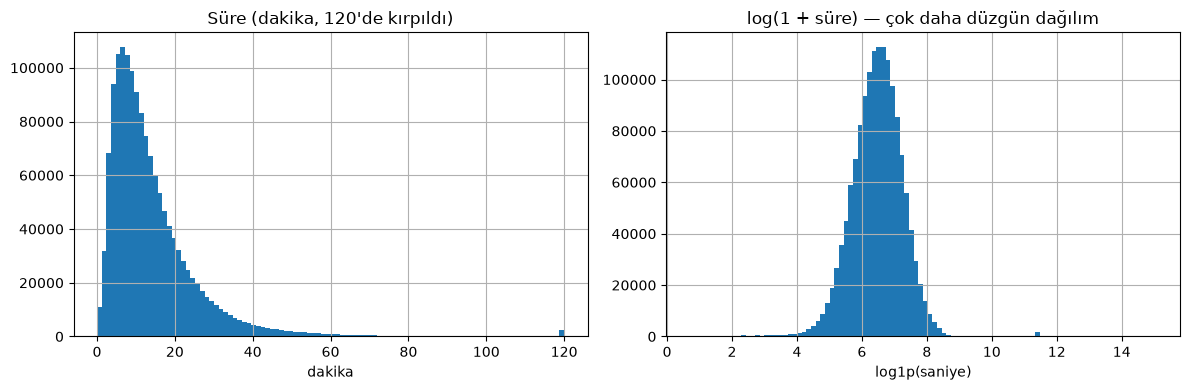

In [7]:
minutes = df["trip_duration"] / 60
print(minutes.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(minutes.clip(upper=120), bins=100)
axes[0].set_title("Süre (dakika, 120'de kırpıldı)")
axes[0].set_xlabel("dakika")
axes[1].hist(np.log1p(df["trip_duration"]), bins=100)
axes[1].set_title("log(1 + süre) — çok daha düzgün dağılım")
axes[1].set_xlabel("log1p(saniye)")
plt.tight_layout()
plt.show()

## 3. Temizlik

Mantıksız kayıtları çıkarıyoruz:

- **Süre:** 1 dakikadan kısa veya 3 saatten uzun yolculuklar (sayaç hataları)
- **Konum:** New York sınırları dışındaki koordinatlar
- **Yolcu sayısı:** 0 veya 6'dan fazla
- **Mesafe:** Neredeyse sıfır mesafe (100 m altı) — bunu mesafeyi hesapladıktan sonra yapıyoruz

In [8]:
NYC_LAT = (40.49, 40.92)
NYC_LON = (-74.27, -73.68)

n_before = len(df)
mask = (
    df["trip_duration"].between(60, 3 * 3600)
    & df["pickup_latitude"].between(*NYC_LAT)
    & df["dropoff_latitude"].between(*NYC_LAT)
    & df["pickup_longitude"].between(*NYC_LON)
    & df["dropoff_longitude"].between(*NYC_LON)
    & df["passenger_count"].between(1, 6)
)
df = df[mask].reset_index(drop=True)
print(f"Çıkarılan satır: {n_before - len(df):,} ({(n_before - len(df)) / n_before:.2%})")
print(f"Kalan satır: {len(df):,}")

Çıkarılan satır: 11,768 (0.81%)
Kalan satır: 1,446,876


## 4. Özellik mühendisliği

Model ham koordinatlardan çok, onlardan türetilen bilgilerden öğrenir:

| Özellik | Açıklama |
| --- | --- |
| `haversine_km` | İki nokta arası kuş uçuşu mesafe |
| `manhattan_km` | Kuzey-güney + doğu-batı mesafe (şehirde ızgara yollar için daha gerçekçi) |
| `bearing` | Yolculuğun yönü (derece) |
| `hour`, `dow`, `month` | Saat, haftanın günü, ay |
| `is_weekend`, `is_rush_hour` | Hafta sonu ve trafik saati bayrakları |
| `pickup_cluster`, `dropoff_cluster` | Şehri 40 bölgeye ayırıp hangi bölgeden hangi bölgeye gidildiği |

`build_features` fonksiyonunu ayrı yazıyoruz çünkü **aynı fonksiyonu ileride FastAPI servisinde** de kullanacağız. Eğitimde ve canlı sistemde özelliklerin aynı şekilde hesaplanması çok önemli.

In [9]:
EARTH_RADIUS_KM = 6371.0

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(a))

def manhattan_km(lat1, lon1, lat2, lon2):
    return haversine_km(lat1, lon1, lat1, lon2) + haversine_km(lat1, lon1, lat2, lon1)

def bearing_deg(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    dlon = lon2 - lon1
    y = np.sin(dlon) * np.cos(lat2)
    x = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
    return np.degrees(np.arctan2(y, x))

def build_features(d, kmeans):
    # Ham sütunlardan modelin kullandığı özellikleri üretir (eğitimde ve API'de aynı).
    out = pd.DataFrame(index=d.index)
    plat, plon = d["pickup_latitude"].values, d["pickup_longitude"].values
    dlat, dlon = d["dropoff_latitude"].values, d["dropoff_longitude"].values
    out["pickup_latitude"], out["pickup_longitude"] = plat, plon
    out["dropoff_latitude"], out["dropoff_longitude"] = dlat, dlon
    out["haversine_km"] = haversine_km(plat, plon, dlat, dlon)
    out["manhattan_km"] = manhattan_km(plat, plon, dlat, dlon)
    out["bearing"] = bearing_deg(plat, plon, dlat, dlon)

    t = d["pickup_datetime"]
    out["hour"] = t.dt.hour
    out["minute_of_day"] = t.dt.hour * 60 + t.dt.minute
    out["dow"] = t.dt.dayofweek          # 0 = Pazartesi
    out["month"] = t.dt.month
    out["is_weekend"] = (out["dow"] >= 5).astype(int)
    out["is_rush_hour"] = (out["hour"].isin([7, 8, 9, 16, 17, 18, 19]) & (out["is_weekend"] == 0)).astype(int)

    out["pickup_cluster"] = kmeans.predict(np.column_stack([plat, plon]))
    out["dropoff_cluster"] = kmeans.predict(np.column_stack([dlat, dlon]))
    out["vendor_id"] = d["vendor_id"].values
    out["passenger_count"] = d["passenger_count"].values
    return out

In [10]:
# Şehri 40 bölgeye ayır (alış ve bırakış noktalarının hepsiyle)
coords = np.vstack([
    df[["pickup_latitude", "pickup_longitude"]].values,
    df[["dropoff_latitude", "dropoff_longitude"]].values,
])
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(coords), size=min(500_000, len(coords)), replace=False)
kmeans = MiniBatchKMeans(n_clusters=40, batch_size=10_000, random_state=RANDOM_STATE, n_init=3)
kmeans.fit(coords[sample_idx])

feats = build_features(df, kmeans)

# Neredeyse sıfır mesafeli yolculukları çıkar
keep = feats["haversine_km"] > 0.1
print(f"100 m altı çıkarılan: {(~keep).sum():,}")
df, feats = df[keep].reset_index(drop=True), feats[keep].reset_index(drop=True)
feats.head()

C:\Users\DELL\AppData\Local\Temp\ipykernel_23980\3230607463.py:33: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  out["dow"] = t.dt.dayofweek          # 0 = Pazartesi


100 m altı çıkarılan: 7,437


,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude,haversine_km,manhattan_km,bearing,hour,minute_of_day,dow,month,is_weekend,is_rush_hour,pickup_cluster,dropoff_cluster,vendor_id,passenger_count
0,40.767937,-73.982155,40.765602,-73.964630,1.498521,1.735433,99.970196,17,1044,0,3,0,1,21,3,2,1
1,40.738564,-73.980415,40.731152,-73.999481,1.805507,2.430506,-117.153768,0,43,6,6,1,0,31,24,1,1
2,40.763939,-73.979027,40.710087,-74.005333,6.385098,8.203575,-159.680165,11,695,1,1,0,0,21,7,2,1
3,40.719971,-74.010040,40.706718,-74.012268,1.485498,1.661331,-172.737700,19,1172,2,4,0,1,7,7,2,1
4,40.793209,-73.973053,40.782520,-73.972923,1.188588,1.199457,179.473585,13,810,5,3,1,0,33,33,2,1


## 5. Zaman ve konum analizi

Ortalama hızın saate ve güne göre nasıl değiştiğine bakıyoruz. Bu grafikler raporda **"neden sadece mesafeye bakmak yetmez"** sorusunun cevabı olacak: aynı mesafe sabah 8'de ve gece 3'te çok farklı sürer.

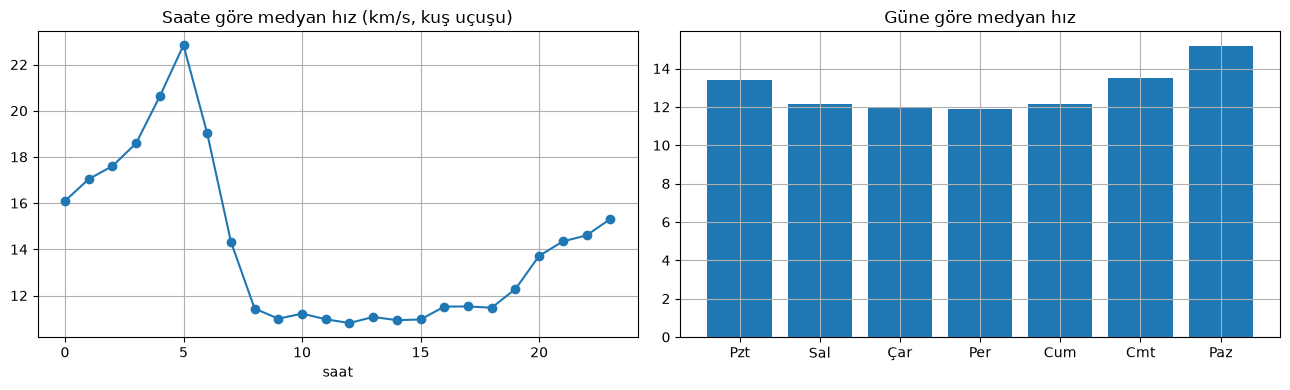

In [11]:
df["speed_kmh"] = feats["haversine_km"] / (df["trip_duration"] / 3600)
df["hour"], df["dow"] = feats["hour"], feats["dow"]
gun_adlari = ["Pzt", "Sal", "Çar", "Per", "Cum", "Cmt", "Paz"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df.groupby("hour")["speed_kmh"].median().plot(ax=axes[0], marker="o")
axes[0].set_title("Saate göre medyan hız (km/s, kuş uçuşu)")
axes[0].set_xlabel("saat")
by_dow = df.groupby("dow")["speed_kmh"].median()
axes[1].bar([gun_adlari[i] for i in by_dow.index], by_dow.values)
axes[1].set_title("Güne göre medyan hız")
plt.tight_layout()
plt.show()

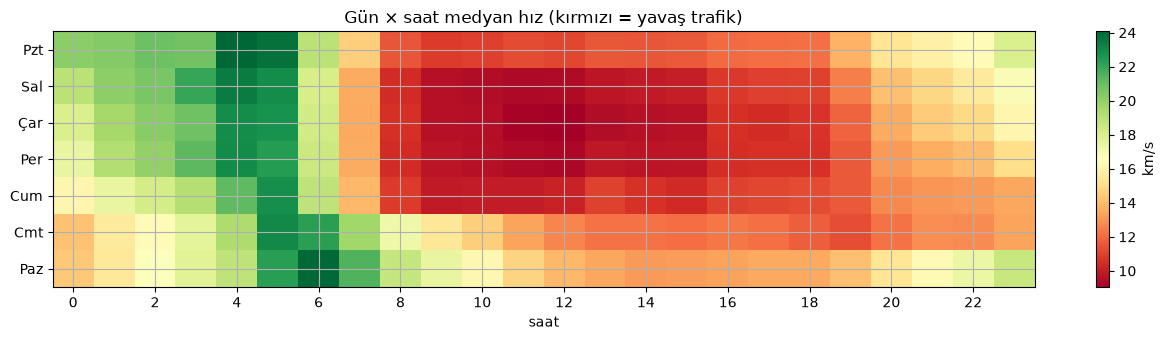

In [12]:
pivot = df.pivot_table(index="dow", columns="hour", values="speed_kmh", aggfunc="median")
fig, ax = plt.subplots(figsize=(13, 3.5))
im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn")
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels([gun_adlari[i] for i in pivot.index])
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("saat")
ax.set_title("Gün × saat medyan hız (kırmızı = yavaş trafik)")
fig.colorbar(im, ax=ax, label="km/s")
plt.tight_layout()
plt.show()

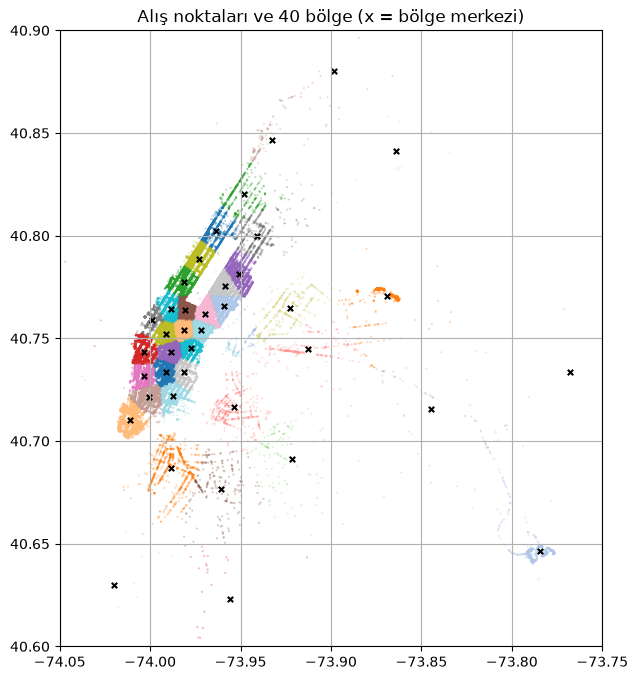

In [13]:
s = df.sample(min(100_000, len(df)), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(7, 8))
ax.scatter(s["pickup_longitude"], s["pickup_latitude"], s=0.3, alpha=0.3,
           c=kmeans.predict(s[["pickup_latitude", "pickup_longitude"]].values), cmap="tab20")
centers = kmeans.cluster_centers_
ax.scatter(centers[:, 1], centers[:, 0], c="black", s=15, marker="x")
ax.set_xlim(-74.05, -73.75)
ax.set_ylim(40.60, 40.90)
ax.set_title("Alış noktaları ve 40 bölge (x = bölge merkezi)")
plt.show()

## 6. Eğitim ve test verisi

Verinin %80'i ile eğitip %20'si ile test ediyoruz. Hedef değişken `log1p(trip_duration)`.

In [14]:
FEATURES = list(feats.columns)
X = feats[FEATURES]
y = np.log1p(df["trip_duration"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Eğitim: {len(X_train):,}  Test: {len(X_test):,}  Özellik sayısı: {len(FEATURES)}")

Eğitim: 1,151,551  Test: 287,888  Özellik sayısı: 17


## 7. Modeller

Üç modeli **aynı test verisi** üzerinde karşılaştırıyoruz:

| Metrik | Anlamı |
| --- | --- |
| **RMSLE** | Kaggle'ın metriği; oransal hatayı ölçer (düşük = iyi) |
| **MAE (dk)** | Ortalama kaç dakika yanılıyoruz |
| **RMSE (dk)** | Büyük hataları daha çok cezalandıran hata |

In [15]:
results = []

def evaluate(name, y_true_log, y_pred_log, train_sec=None):
    y_true_log = np.asarray(y_true_log)
    y_pred_log = np.asarray(y_pred_log)
    true_s, pred_s = np.expm1(y_true_log), np.expm1(y_pred_log)
    row = {
        "model": name,
        "RMSLE": float(np.sqrt(mean_squared_error(y_true_log, y_pred_log))),
        "MAE (dk)": float(mean_absolute_error(true_s, pred_s) / 60),
        "RMSE (dk)": float(np.sqrt(mean_squared_error(true_s, pred_s)) / 60),
        "eğitim süresi (sn)": train_sec,
    }
    results.append(row)
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()})

### 7.1 Taban çizgi: mesafe / ortalama hız

Hiç makine öğrenmesi kullanmadan, eğitim verisindeki medyan hızla `süre = mesafe / hız` hesaplıyoruz. Diğer modeller bunu geçemiyorsa işe yaramıyor demektir.

In [16]:
train_speed = X_train["manhattan_km"] / (np.expm1(y_train) / 3600)
median_speed = train_speed.median()
print(f"Medyan hız (manhattan mesafesi ile): {median_speed:.1f} km/s")

baseline_pred = np.log1p(X_test["manhattan_km"] / median_speed * 3600)
evaluate("Taban çizgi (mesafe / hız)", y_test, baseline_pred)

Medyan hız (manhattan mesafesi ile): 16.4 km/s
{'model': 'Taban çizgi (mesafe / hız)', 'RMSLE': 0.5424, 'MAE (dk)': 6.8521, 'RMSE (dk)': 12.9326, 'eğitim süresi (sn)': None}


### 7.2 Linear Regression

In [17]:
t0 = time.time()
lin = LinearRegression()
lin.fit(X_train, y_train)
evaluate("Linear Regression", y_test, lin.predict(X_test), time.time() - t0)

{'model': 'Linear Regression', 'RMSLE': 0.5177, 'MAE (dk)': 5.7718, 'RMSE (dk)': 16.8162, 'eğitim süresi (sn)': 4.8557}


### 7.3 XGBoost

Eğitim verisinin bir kısmını **doğrulama (validation)** için ayırıp `early_stopping` kullanıyoruz: doğrulama hatası 50 tur boyunca iyileşmezse eğitim durur. Böylece aşırı öğrenme (overfitting) önlenir.

> Hiper-parametre ayarı 4. haftanın işi; burada makul varsayılanlarla başlıyoruz.

In [18]:
from xgboost import XGBRegressor

X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=RANDOM_STATE)

t0 = time.time()
xgb = XGBRegressor(
    n_estimators=2000,
    learning_rate=0.1,
    max_depth=8,
    min_child_weight=10,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    early_stopping_rounds=50,
    eval_metric="rmse",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
xgb.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=200)
evaluate("XGBoost", y_test, xgb.predict(X_test), time.time() - t0)

[0]	validation_0-rmse:0.67410
[200]	validation_0-rmse:0.30605
[400]	validation_0-rmse:0.30120
[600]	validation_0-rmse:0.29901
[800]	validation_0-rmse:0.29779
[1000]	validation_0-rmse:0.29713
[1172]	validation_0-rmse:0.29675
{'model': 'XGBoost', 'RMSLE': 0.2961, 'MAE (dk)': 2.7183, 'RMSE (dk)': 4.5947, 'eğitim süresi (sn)': 629.5435}


## 8. Sonuçlar

Bu tablo ve grafik doğrudan bitirme raporuna girebilir.

,RMSLE,MAE (dk),RMSE (dk),eğitim süresi (sn),taban çizgiye göre iyileşme
model,,,,,
Taban çizgi (mesafe / hız),0.542,6.852,12.933,NaN,0.0%
Linear Regression,0.518,5.772,16.816,4.856,4.5%
XGBoost,0.296,2.718,4.595,629.544,45.4%


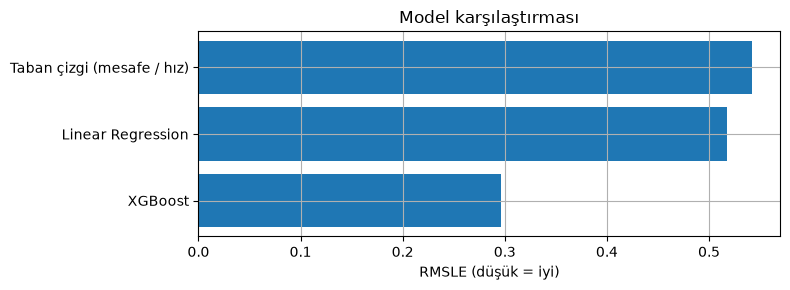

In [19]:
res = pd.DataFrame(results).set_index("model")
base = res.loc["Taban çizgi (mesafe / hız)", "RMSLE"]
res["taban çizgiye göre iyileşme"] = ((base - res["RMSLE"]) / base).map("{:.1%}".format)
display(res.round(3))

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(res.index, res["RMSLE"])
ax.invert_yaxis()
ax.set_xlabel("RMSLE (düşük = iyi)")
ax.set_title("Model karşılaştırması")
plt.tight_layout()
plt.show()

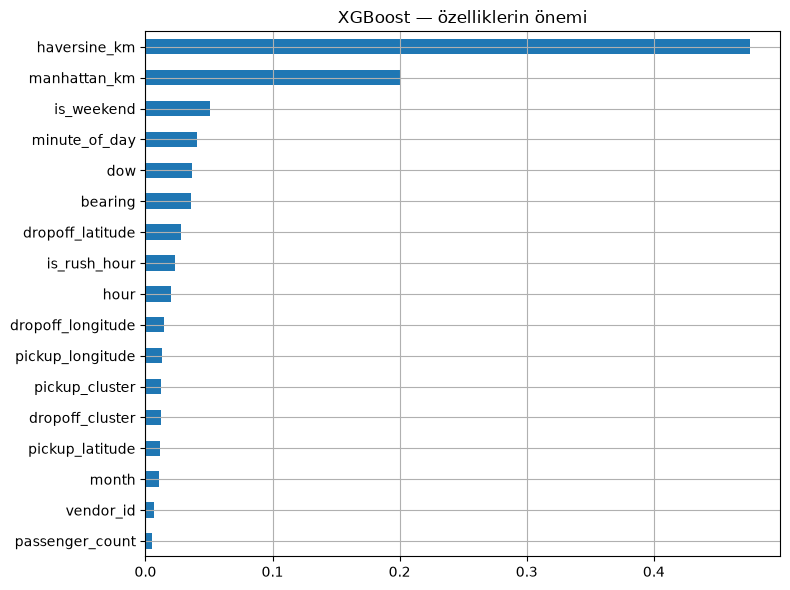

In [20]:
imp = pd.Series(xgb.feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(figsize=(8, 6), title="XGBoost — özelliklerin önemi")
plt.tight_layout()
plt.show()

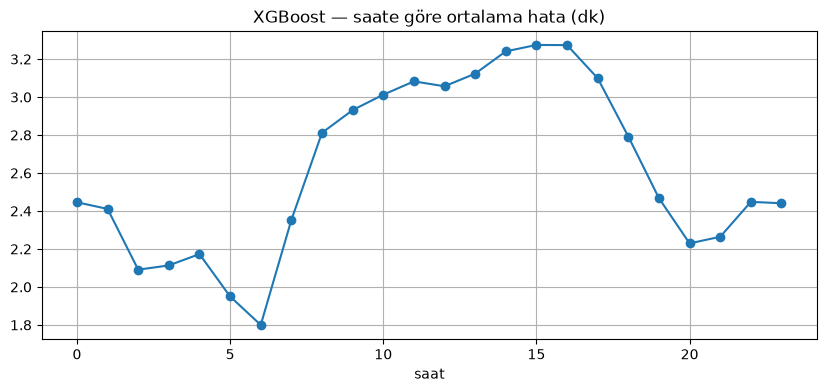

In [21]:
# Hata saate göre nasıl değişiyor? (Yoğun saatlerde model zorlanıyor mu?)
test_err = pd.DataFrame({
    "hour": X_test["hour"].values,
    "abs_err_dk": np.abs(np.expm1(xgb.predict(X_test)) - np.expm1(y_test.values)) / 60,
})
test_err.groupby("hour")["abs_err_dk"].mean().plot(marker="o", title="XGBoost — saate göre ortalama hata (dk)")
plt.xlabel("saat")
plt.show()

### Modeli kaydet

Bu üç dosyayı 5. haftada AI servisine (FastAPI) yükleyeceğiz.

In [22]:
joblib.dump(xgb, MODEL_DIR / "eta_xgb.joblib")
joblib.dump(kmeans, MODEL_DIR / "kmeans_40.joblib")
(MODEL_DIR / "eta_features.json").write_text(json.dumps(FEATURES, indent=2))
print("Kaydedildi:", [p.name for p in MODEL_DIR.iterdir()])

Kaydedildi: ['eta_features.json', 'eta_xgb.joblib', 'kmeans_40.joblib']


## 9. Bonus: model + OR-Tools ile ilk rota

Projenin ana fikrini küçük ölçekte deniyoruz:

1. Bir depo ve 10 teslimat noktası seçiyoruz (verideki gerçek bırakış noktalarından).
2. XGBoost ile **her nokta çifti arasındaki süreyi** tahmin edip bir süre matrisi oluşturuyoruz.
3. OR-Tools ile 3 aracı bu noktalara dağıtıp toplam süreyi en aza indiriyoruz.
4. Sonucu basit bir **açgözlü (greedy) en yakın komşu** yöntemiyle karşılaştırıyoruz.

In [23]:
def eta_matrix(points, when, model, kmeans):
    # points: [(lat, lon), ...] -> saniye cinsinden n x n süre matrisi
    n = len(points)
    pairs = [(i, j) for i in range(n) for j in range(n) if i != j]
    raw = pd.DataFrame({
        "pickup_latitude":  [points[i][0] for i, _ in pairs],
        "pickup_longitude": [points[i][1] for i, _ in pairs],
        "dropoff_latitude":  [points[j][0] for _, j in pairs],
        "dropoff_longitude": [points[j][1] for _, j in pairs],
        "pickup_datetime": pd.to_datetime([when] * len(pairs)),
        "vendor_id": 1,
        "passenger_count": 1,
    })
    pred = np.expm1(model.predict(build_features(raw, kmeans)[FEATURES]))
    M = np.zeros((n, n), dtype=int)
    for (i, j), sec in zip(pairs, pred):
        M[i, j] = int(round(sec))
    return M

demo = df[df["dropoff_latitude"].between(40.70, 40.80) & df["dropoff_longitude"].between(-74.02, -73.95)]
demo = demo.sample(11, random_state=7)
points = list(zip(demo["dropoff_latitude"], demo["dropoff_longitude"]))   # 0 = depo, 1..10 = teslimat
WHEN = "2016-04-12 17:30:00"   # Salı akşam trafiği

M = eta_matrix(points, WHEN, xgb, kmeans)
print("Süre matrisi (dakika), ilk 5x5:")
print((M[:5, :5] / 60).round(1))

Süre matrisi (dakika), ilk 5x5:
[[ 0.   9.7 31.   7.1 31.1]
 [ 7.4  0.  29.9  6.4 26. ]
 [28.7 28.9  0.  24.2 10.7]
 [ 7.1  8.2 25.2  0.  21.4]
 [23.6 17.4  8.2 17.4  0. ]]


C:\Users\DELL\AppData\Local\Temp\ipykernel_23980\3230607463.py:33: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  out["dow"] = t.dt.dayofweek          # 0 = Pazartesi


In [24]:
from ortools.constraint_solver import pywrapcp, routing_enums_pb2

def solve_vrp(M, num_vehicles=3, depot=0, time_limit_s=5):
    manager = pywrapcp.RoutingIndexManager(len(M), num_vehicles, depot)
    routing = pywrapcp.RoutingModel(manager)

    def travel_time(from_index, to_index):
        return int(M[manager.IndexToNode(from_index)][manager.IndexToNode(to_index)])

    transit = routing.RegisterTransitCallback(travel_time)
    routing.SetArcCostEvaluatorOfAllVehicles(transit)

    # Her aracın toplam süresi en fazla 3 saat; en uzun rotayı kısaltmaya çalış (yükü dengeler)
    routing.AddDimension(transit, 0, 3 * 3600, True, "Time")
    routing.GetDimensionOrDie("Time").SetGlobalSpanCostCoefficient(100)

    params = pywrapcp.DefaultRoutingSearchParameters()
    params.first_solution_strategy = routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC
    params.local_search_metaheuristic = routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    params.time_limit.FromSeconds(time_limit_s)

    solution = routing.SolveWithParameters(params)
    if solution is None:
        raise RuntimeError("Çözüm bulunamadı")

    routes = []
    for v in range(num_vehicles):
        index, route = routing.Start(v), []
        while not routing.IsEnd(index):
            route.append(manager.IndexToNode(index))
            index = solution.Value(routing.NextVar(index))
        route.append(manager.IndexToNode(index))
        routes.append(route)
    return routes

def route_time(route, M):
    return sum(M[a][b] for a, b in zip(route, route[1:]))

def greedy_routes(M, num_vehicles=3, depot=0):
    # Karşılaştırma için: araçlar sırayla en yakın ziyaret edilmemiş noktaya gider
    unvisited = set(range(len(M))) - {depot}
    routes = [[depot] for _ in range(num_vehicles)]
    v = 0
    while unvisited:
        last = routes[v][-1]
        nxt = min(unvisited, key=lambda j: M[last][j])
        routes[v].append(nxt)
        unvisited.remove(nxt)
        v = (v + 1) % num_vehicles
    return [r + [depot] for r in routes]

def report(name, routes, M):
    times = [route_time(r, M) / 60 for r in routes]
    print(f"\n{name}")
    for v, (r, t) in enumerate(zip(routes, times)):
        print(f"  Araç {v + 1}: {' -> '.join(map(str, r))}   ({t:.1f} dk)")
    print(f"  Toplam: {sum(times):.1f} dk   |   En uzun rota: {max(times):.1f} dk")
    return sum(times), max(times)

t0 = time.time()
ort_routes = solve_vrp(M)
print(f"OR-Tools çözüm süresi: {time.time() - t0:.1f} sn")
ort_total, ort_max = report("OR-Tools", ort_routes, M)
gr_total, gr_max = report("Greedy (en yakın komşu)", greedy_routes(M), M)
print(f"\nToplam süre: OR-Tools, greedy'ye göre %{(gr_total - ort_total) / gr_total * 100:.1f} daha kısa")
print(f"En uzun rota: OR-Tools, greedy'ye göre %{(gr_max - ort_max) / gr_max * 100:.1f} daha kısa")

OR-Tools çözüm süresi: 5.2 sn

OR-Tools
  Araç 1: 0 -> 9 -> 2 -> 4 -> 1 -> 0   (66.2 dk)
  Araç 2: 0 -> 7 -> 5 -> 0   (59.2 dk)
  Araç 3: 0 -> 3 -> 6 -> 8 -> 10 -> 0   (66.8 dk)
  Toplam: 192.2 dk   |   En uzun rota: 66.8 dk

Greedy (en yakın komşu)
  Araç 1: 0 -> 10 -> 9 -> 5 -> 8 -> 0   (90.7 dk)
  Araç 2: 0 -> 3 -> 7 -> 2 -> 0   (88.9 dk)
  Araç 3: 0 -> 1 -> 4 -> 6 -> 0   (76.8 dk)
  Toplam: 256.4 dk   |   En uzun rota: 90.7 dk

Toplam süre: OR-Tools, greedy'ye göre %25.0 daha kısa
En uzun rota: OR-Tools, greedy'ye göre %26.4 daha kısa


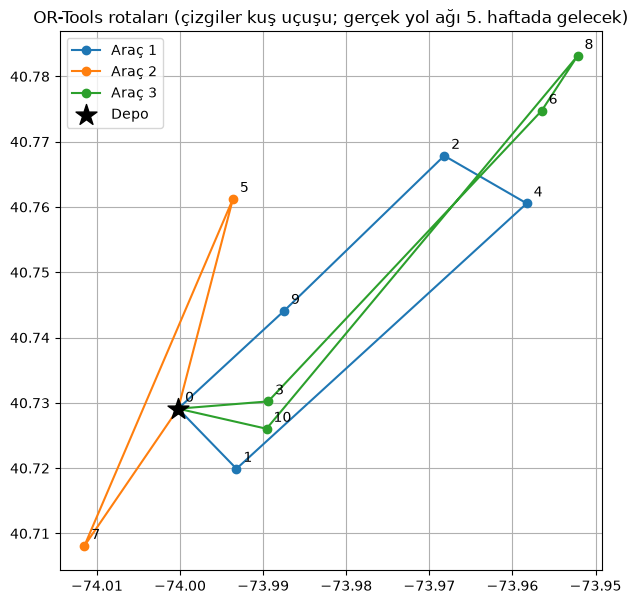

In [25]:
fig, ax = plt.subplots(figsize=(7, 7))
lats, lons = zip(*points)
renkler = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]
for v, r in enumerate(ort_routes):
    ax.plot([lons[i] for i in r], [lats[i] for i in r], "-o", color=renkler[v % 5], label=f"Araç {v + 1}")
ax.scatter(lons[0], lats[0], s=250, marker="*", color="black", zorder=5, label="Depo")
for i, (la, lo) in enumerate(points):
    ax.annotate(str(i), (lo, la), textcoords="offset points", xytext=(5, 5))
ax.set_title("OR-Tools rotaları (çizgiler kuş uçuşu; gerçek yol ağı 5. haftada gelecek)")
ax.legend()
plt.show()

## Sonraki adımlar

- [ ] Sonuç tablosunu ve grafikleri hocana göster
- [ ] 4. hafta: XGBoost hiper-parametre ayarı (Optuna veya `RandomizedSearchCV`)
- [ ] Ek özellik denemesi: tatil günleri, havalimanı bayrakları, bölge çiftine göre ortalama hız
- [ ] 5. hafta: `models/` klasöründeki dosyaları FastAPI'de `/predict-eta` olarak sun
- [ ] 7. hafta: `solve_vrp` fonksiyonunu `/optimize-routes` servisine taşı